# Mission EdStats : supprimer les indicateurs redondants (phase 3)

La phase 2 a produit le tableau final pays × indicateurs (`country_indicator_final.csv` dans `data/output/`). Certains de ces indicateurs mesurent quasiment la même chose : pour academy, ils apportent la même information et alourdissent l'analyse sans rien y ajouter.

**Objectif** : ne garder que les indicateurs faiblement corrélés entre eux, c'est-à-dire un coefficient de corrélation (corrélation) inférieur à 0,70 en valeur absolue.

Plan de ce notebook : charger les CSV réduits de `data/output/` (section 1), déterminer le seuil de valeurs manquantes (section 2), calculer les matrices de corrélation de Pearson puis de Spearman et les visualiser en heatmap (carte de chaleur) (section 3), repérer les paires trop corrélées et choisir l'indicateur à garder (section 4), écrire le tableau réduit dans `data/output/` (section 5).

Flux des données : `data/output/` (entrée, produit par la phase 2) → ce notebook → `data/output/` (livrable de la phase 3).

## 1. Charger les CSV réduits de la phase 2

Les entrées de cette analyse sont les CSV écrits par la phase 2 dans `data/output/` : `country_indicator_final.csv` (tableau final pays × indicateurs) et `EdStatsSeries.csv` (nom complet de chaque code d'indicateur).

### 1.1 Dossiers et lecture

`load_csv_output()` lit un CSV de `data/output/`, que le notebook soit lancé depuis la racine du projet ou depuis `notebooks/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

candidates = [
    Path.cwd() / "data" / "output",         # from the project root
    Path.cwd() / ".." / "data" / "output",  # from notebooks/
]

OUTPUT_DIR = None
for candidate in candidates:
    if candidate.exists():
        OUTPUT_DIR = candidate.resolve()
        break
if OUTPUT_DIR is None:
    raise FileNotFoundError("data/output/ not found")

def load_csv_output(name, columns=None):
    """Read the CSV `name` from OUTPUT_DIR as is, optionally keeping only `columns`."""
    return pd.read_csv(OUTPUT_DIR / name, encoding="utf-8", usecols=columns)

OUTPUT_DIR

PosixPath('/Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output')

### 1.2 Le tableau final pays × indicateurs

Chargé une seule fois dans `final_table` et réutilisé par toutes les cellules suivantes : aucune opération ne modifie ce DataFrame en place, on recharge le CSV si besoin. Aperçu des 3 premières lignes :

In [2]:
# load once, reused by every cell of this notebook
final_table = load_csv_output("country_indicator_final.csv")
final_table.head(3)

,Country Code,Country Name,IT.NET.USER.P2,SP.SEC.UTOT.IN,SP.TER.TOTL.IN,SE.SEC.ENRL.GC,SE.TER.ENRL,SE.SEC.ENRR.UP,SE.TER.ENRR,SE.TOT.ENRR,PRJ.MYS.0T19.MF,PRJ.MYS.15UP.MF,PRJ.MYS.1519.MF,NY.GDP.PCAP.CD,SE.SEC.ENRL.TC.ZS,SE.XPD.TOTL.GD.ZS
0,ABW,Aruba,60.292077,4.478191e+03,6.799110e+03,6.564050e+03,1879.205882,90.496135,28.226781,85.283390,2.418519,8.777778,8.259259,24357.132282,14.201038,5.872939
1,AFG,Afghanistan,4.332797,1.865566e+06,2.624559e+06,1.910425e+06,137132.434783,32.586328,4.899025,63.099617,NaN,NaN,NaN,489.193612,35.668039,3.342328
2,AGO,Angola,5.180553,1.415692e+06,2.006447e+06,4.112328e+05,139698.582090,17.902200,6.445411,63.723745,NaN,NaN,NaN,3483.189042,25.717081,3.100720


Taille du tableau et liste des colonnes indicateurs (toutes les colonnes sauf `Country Code` et `Country Name`) :

In [3]:
print(f"{final_table.shape[0]} rows, {final_table.shape[1]} columns")

indicator_columns = []
for col in final_table.columns:
    if col not in ("Country Code", "Country Name"):
        indicator_columns.append(col)

print(f"{len(indicator_columns)} indicateurs:")
for col in indicator_columns:
    print(f"  {col}")

214 rows, 16 columns
14 indicateurs:
  IT.NET.USER.P2
  SP.SEC.UTOT.IN
  SP.TER.TOTL.IN
  SE.SEC.ENRL.GC
  SE.TER.ENRL
  SE.SEC.ENRR.UP
  SE.TER.ENRR
  SE.TOT.ENRR
  PRJ.MYS.0T19.MF
  PRJ.MYS.15UP.MF
  PRJ.MYS.1519.MF
  NY.GDP.PCAP.CD
  SE.SEC.ENRL.TC.ZS
  SE.XPD.TOTL.GD.ZS


### 1.3 Le nom des indicateurs

`EdStatsSeries.csv` associe chaque code (ex. `IT.NET.USER.P2`) à son nom complet. Référentiel chargé une seule fois dans `series`, réduit aux seuls indicateurs retenus par la phase 2 :

In [4]:
# load once, reused later for indicator names
series = load_csv_output("EdStatsSeries.csv", columns=["Series Code", "Indicator Name"])
series.head(3)

,Series Code,Indicator Name
0,IT.NET.USER.P2,Internet users (per 100 people)
1,NY.GDP.PCAP.CD,GDP per capita (current US$)
2,PRJ.MYS.0T19.MF,Projection: Mean years of schooling. Age 0-19....


### 1.4 Les valeurs manquantes (point de vigilance)

Point de vigilance : la matrice de corrélation ignore automatiquement les pays où un indicateur est non renseigné, paire par paire, ce qui peut fausser le calcul. Comptage des valeurs manquantes par indicateur et au total, avant toute corrélation :

In [5]:
nb_countries = len(final_table)
total_missing = 0
for col in indicator_columns:
    missing = final_table[col].isna().sum()
    total_missing += missing
    print(f"{col}: {missing} manquantes sur {nb_countries} pays")

total_cells = nb_countries * len(indicator_columns)
print(f"total: {total_missing} valeurs manquantes sur {total_cells} ({total_missing / total_cells:.1%})")

IT.NET.USER.P2: 9 manquantes sur 214 pays
SP.SEC.UTOT.IN: 17 manquantes sur 214 pays
SP.TER.TOTL.IN: 16 manquantes sur 214 pays
SE.SEC.ENRL.GC: 12 manquantes sur 214 pays
SE.TER.ENRL: 21 manquantes sur 214 pays
SE.SEC.ENRR.UP: 23 manquantes sur 214 pays
SE.TER.ENRR: 30 manquantes sur 214 pays
SE.TOT.ENRR: 30 manquantes sur 214 pays
PRJ.MYS.0T19.MF: 48 manquantes sur 214 pays
PRJ.MYS.15UP.MF: 48 manquantes sur 214 pays
PRJ.MYS.1519.MF: 48 manquantes sur 214 pays
NY.GDP.PCAP.CD: 7 manquantes sur 214 pays
SE.SEC.ENRL.TC.ZS: 32 manquantes sur 214 pays
SE.XPD.TOTL.GD.ZS: 32 manquantes sur 214 pays
total: 373 valeurs manquantes sur 2996 (12.4%)


### Bilan de la section 1

Tableau final chargé une seule fois depuis `data/output/`, noms des indicateurs via `EdStatsSeries.csv`, valeurs manquantes comptées par indicateur.

**Décision retenue** : le seuil de valeurs manquantes est déterminé en section 2, avant toute corrélation.

## 2. Seuil de valeurs manquantes

À quoi sert le seuil : un indicateur très troué fausse la matrice de corrélation, car `corr()` ignore les pays non renseignés paire par paire. Le taux de manquantes par indicateur décide si l'indicateur est assez complet pour rester dans l'analyse.

### 2.1 Taux de manquantes par indicateur

Trié du plus troué au plus complet, avec le nom :

In [6]:
# code -> name lookup from the series reference
name_of = {}
for i in range(len(series)):
    name_of[series["Series Code"].iloc[i]] = series["Indicator Name"].iloc[i]

# missing rate per indicator, sorted from most to least incomplete
rows = []
for col in indicator_columns:
    rows.append({
        "indicateur": col,
        "nom": name_of.get(col, ""),
        "taux_manquantes": final_table[col].isna().mean(),
    })

missing_rates = pd.DataFrame(rows).sort_values("taux_manquantes", ascending=False)
missing_rates

,indicateur,nom,taux_manquantes
8,PRJ.MYS.0T19.MF,Projection: Mean years of schooling. Age 0-19....,0.224299
9,PRJ.MYS.15UP.MF,Projection: Mean years of schooling. Age 15+. ...,0.224299
10,PRJ.MYS.1519.MF,Projection: Mean years of schooling. Age 15-19...,0.224299
12,SE.SEC.ENRL.TC.ZS,Pupil-teacher ratio in secondary education (he...,0.149533
13,SE.XPD.TOTL.GD.ZS,Government expenditure on education as % of GD...,0.149533
6,SE.TER.ENRR,"Gross enrolment ratio, tertiary, both sexes (%)",0.140187
7,SE.TOT.ENRR,"Gross enrolment ratio, primary to tertiary, bo...",0.140187
5,SE.SEC.ENRR.UP,"Gross enrolment ratio, upper secondary, both s...",0.107477
4,SE.TER.ENRL,"Enrolment in tertiary education, all programme...",0.098131
1,SP.SEC.UTOT.IN,Population of the official age for upper secon...,0.079439


In [7]:
# basis for the threshold: max missing rate outside the projections, and the projections' own rates
prj_codes = []
non_prj_codes = []
for col in indicator_columns:
    if col.startswith("PRJ."):
        prj_codes.append(col)
    else:
        non_prj_codes.append(col)

max_rate = 0
max_col = ""
for col in non_prj_codes:
    rate = final_table[col].isna().mean()
    if rate > max_rate:
        max_rate = rate
        max_col = col
nb_missing_max = int(final_table[max_col].isna().sum())
print(f"taux max hors projections : {nb_missing_max} manquantes sur {len(final_table)} pays = {max_rate:.2%} ({max_col})")

for col in prj_codes:
    nb = int(final_table[col].isna().sum())
    print(f"projection {col} : {nb} manquantes sur {len(final_table)} = {final_table[col].isna().mean():.2%}")

taux max hors projections : 32 manquantes sur 214 pays = 14.95% (SE.SEC.ENRL.TC.ZS)
projection PRJ.MYS.0T19.MF : 48 manquantes sur 214 = 22.43%
projection PRJ.MYS.15UP.MF : 48 manquantes sur 214 = 22.43%
projection PRJ.MYS.1519.MF : 48 manquantes sur 214 = 22.43%


**Conclusion** : seuil retenu **14,9 %** (14,95 % au brut : 32 pays manquants sur 214 hors projections), jugé raisonnable : tous les indicateurs passent le seuil, on les garde tous.

Note : les trois projections `PRJ.*` ont exactement le même taux (22,43 %, 48 pays sur 214 chacune), une certaine constance dans les données : on les garde aussi.

## 3. Matrices de corrélation

Deux méthodes sur les 14 indicateurs de `final_table` tel quel (`corr()` ignore les pays manquants paire par paire) :

- **Pearson** : relation linéaire, travaille sur les valeurs brutes, sensible aux valeurs extrêmes (outliers) ;
- **Spearman** : relation monotone, travaille sur les rangs, robuste aux outliers.

### 3.1 Matrice de Pearson

`corr(method="pearson")` sur les colonnes indicateurs :

In [8]:
corr_pearson = final_table[indicator_columns].corr(method="pearson")
corr_pearson

,IT.NET.USER.P2,SP.SEC.UTOT.IN,SP.TER.TOTL.IN,SE.SEC.ENRL.GC,SE.TER.ENRL,SE.SEC.ENRR.UP,SE.TER.ENRR,SE.TOT.ENRR,PRJ.MYS.0T19.MF,PRJ.MYS.15UP.MF,PRJ.MYS.1519.MF,NY.GDP.PCAP.CD,SE.SEC.ENRL.TC.ZS,SE.XPD.TOTL.GD.ZS
IT.NET.USER.P2,1.000000,-0.081363,-0.067672,-0.048983,0.054977,0.800107,0.751145,0.760585,0.723878,0.806172,0.686500,0.755239,-0.638840,0.044906
SP.SEC.UTOT.IN,-0.081363,1.000000,0.975943,0.988203,0.848301,-0.055695,-0.053383,-0.073182,-0.010459,-0.088910,-0.019634,-0.073330,0.102616,-0.086465
SP.TER.TOTL.IN,-0.067672,0.975943,1.000000,0.981658,0.911904,-0.040610,-0.037233,-0.057507,0.010327,-0.073565,-0.000353,-0.071174,0.088737,-0.091933
SE.SEC.ENRL.GC,-0.048983,0.988203,0.981658,1.000000,0.902064,-0.009637,-0.006028,-0.020674,0.025038,-0.048858,0.019326,-0.059316,0.084905,-0.063679
SE.TER.ENRL,0.054977,0.848301,0.911904,0.902064,1.000000,0.074138,0.136908,0.086983,0.113087,0.056584,0.104984,0.004715,-0.004118,-0.036352
SE.SEC.ENRR.UP,0.800107,-0.055695,-0.040610,-0.009637,0.074138,1.000000,0.812728,0.865568,0.778664,0.847211,0.777489,0.572392,-0.670357,0.184241
SE.TER.ENRR,0.751145,-0.053383,-0.037233,-0.006028,0.136908,0.812728,1.000000,0.851002,0.686786,0.764764,0.655931,0.452127,-0.567275,0.189936
SE.TOT.ENRR,0.760585,-0.073182,-0.057507,-0.020674,0.086983,0.865568,0.851002,1.000000,0.753625,0.816520,0.756862,0.479147,-0.634417,0.204228
PRJ.MYS.0T19.MF,0.723878,-0.010459,0.010327,0.025038,0.113087,0.778664,0.686786,0.753625,1.000000,0.880660,0.952120,0.461958,-0.570757,0.243853
PRJ.MYS.15UP.MF,0.806172,-0.088910,-0.073565,-0.048858,0.056584,0.847211,0.764764,0.816520,0.880660,1.000000,0.899242,0.582665,-0.626190,0.256707


### 3.2 Heatmap de Pearson (carte de chaleur)

Lecture : chaque case est le coefficient entre l'indicateur en ligne et celui en colonne, la diagonale vaut 1. Rouge = corrélation positive, bleu = négative, blanc = proche de 0. Les cases foncées hors diagonale sont les paires fortement corrélées :

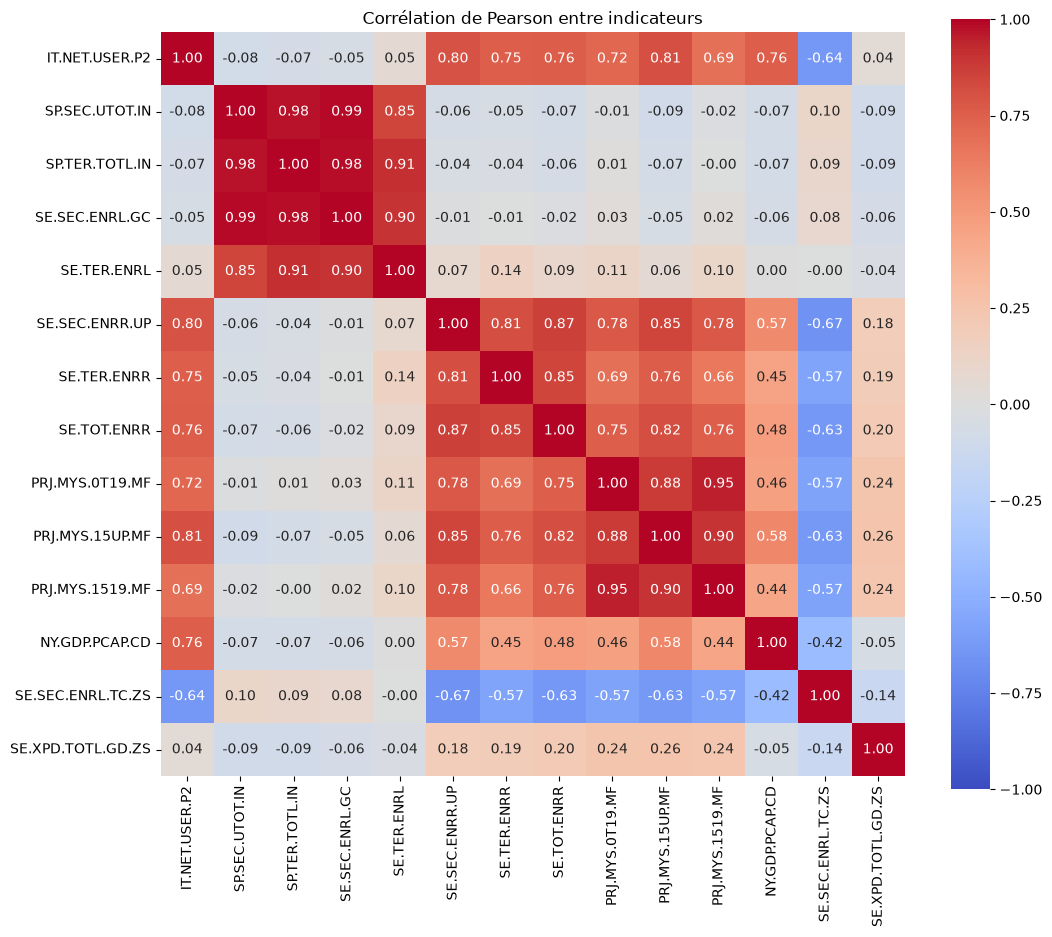

In [9]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélation de Pearson entre indicateurs")
plt.show()

### 3.3 Matrice de Spearman

`corr(method="spearman")` :

In [10]:
corr_spearman = final_table[indicator_columns].corr(method="spearman")
corr_spearman

,IT.NET.USER.P2,SP.SEC.UTOT.IN,SP.TER.TOTL.IN,SE.SEC.ENRL.GC,SE.TER.ENRL,SE.SEC.ENRR.UP,SE.TER.ENRR,SE.TOT.ENRR,PRJ.MYS.0T19.MF,PRJ.MYS.15UP.MF,PRJ.MYS.1519.MF,NY.GDP.PCAP.CD,SE.SEC.ENRL.TC.ZS,SE.XPD.TOTL.GD.ZS
IT.NET.USER.P2,1.000000,-0.220365,-0.206995,-0.126081,0.188388,0.822493,0.796789,0.810196,0.768419,0.842403,0.737355,0.921508,-0.734495,0.156483
SP.SEC.UTOT.IN,-0.220365,1.000000,0.990436,0.956149,0.828886,-0.166692,-0.019799,-0.123244,-0.202930,-0.192787,-0.171740,-0.265504,0.305970,-0.168790
SP.TER.TOTL.IN,-0.206995,0.990436,1.000000,0.971612,0.847090,-0.140826,0.006130,-0.096692,-0.192217,-0.176919,-0.145129,-0.254806,0.289080,-0.162169
SE.SEC.ENRL.GC,-0.126081,0.956149,0.971612,1.000000,0.903245,0.004166,0.122735,0.014128,-0.069060,-0.043565,-0.013290,-0.180057,0.243306,-0.076505
SE.TER.ENRL,0.188388,0.828886,0.847090,0.903245,1.000000,0.284628,0.484252,0.315163,0.270854,0.284484,0.289704,0.103799,-0.031362,0.038314
SE.SEC.ENRR.UP,0.822493,-0.166692,-0.140826,0.004166,0.284628,1.000000,0.846452,0.874926,0.746335,0.864835,0.747174,0.815343,-0.716609,0.233240
SE.TER.ENRR,0.796789,-0.019799,0.006130,0.122735,0.484252,0.846452,1.000000,0.897152,0.727749,0.793935,0.698327,0.752023,-0.650777,0.246727
SE.TOT.ENRR,0.810196,-0.123244,-0.096692,0.014128,0.315163,0.874926,0.897152,1.000000,0.696027,0.801552,0.693037,0.788673,-0.633777,0.275302
PRJ.MYS.0T19.MF,0.768419,-0.202930,-0.192217,-0.069060,0.270854,0.746335,0.727749,0.696027,1.000000,0.830584,0.916689,0.726552,-0.624487,0.251419
PRJ.MYS.15UP.MF,0.842403,-0.192787,-0.176919,-0.043565,0.284484,0.864835,0.793935,0.801552,0.830584,1.000000,0.843110,0.802005,-0.703331,0.274559


### 3.4 Heatmap de Spearman (carte de chaleur)

Même lecture que la heatmap de Pearson :

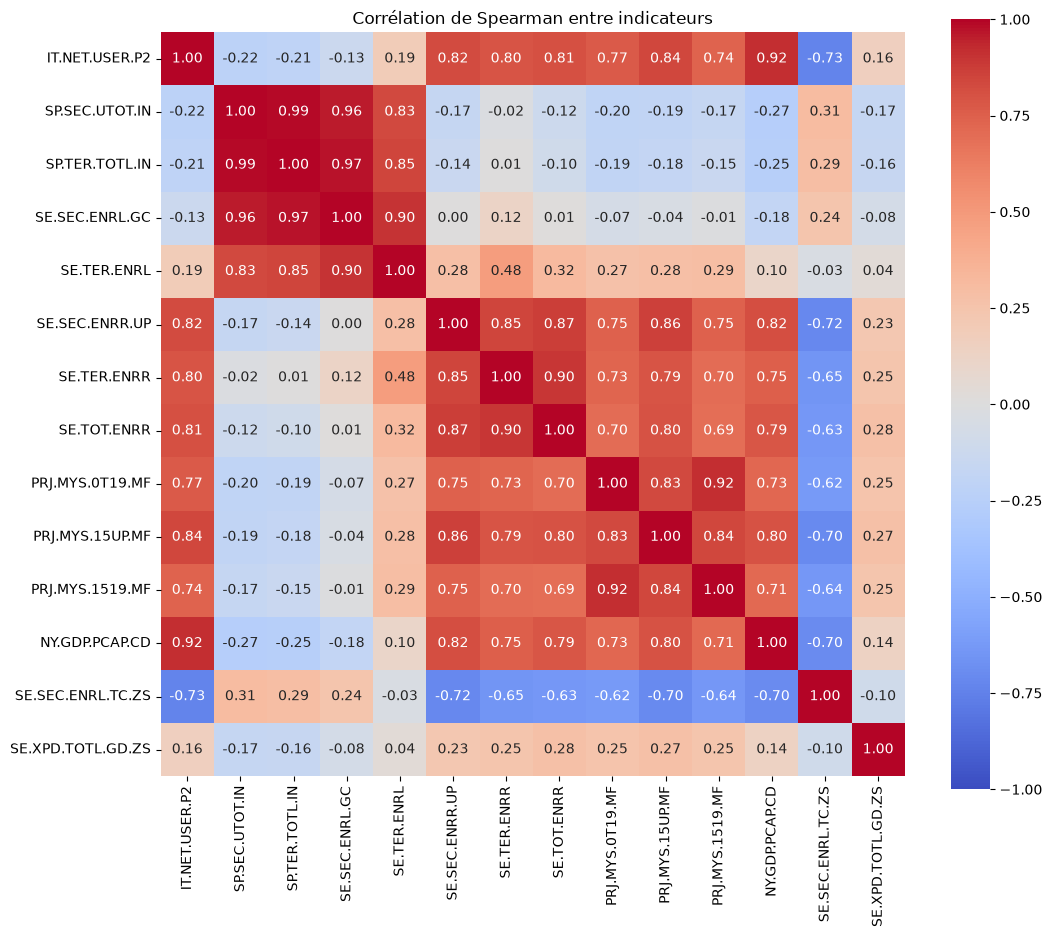

In [11]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélation de Spearman entre indicateurs")
plt.show()

### 3.5 Pearson vs Spearman

Là où les deux méthodes divergent, ce sont des valeurs extrêmes (outliers) qui tirent Pearson. Les 10 paires avec le plus grand écart entre les deux coefficients :

In [12]:
# one row per pair of indicators (upper triangle, no diagonal), with both coefficients and their gap
pairs = []
for i in range(len(indicator_columns)):
    for j in range(i + 1, len(indicator_columns)):
        a = indicator_columns[i]
        b = indicator_columns[j]
        pairs.append({
            "paire": f"{a} / {b}",
            "pearson": corr_pearson.loc[a, b],
            "spearman": corr_spearman.loc[a, b],
            "ecart": abs(corr_pearson.loc[a, b] - corr_spearman.loc[a, b]),
        })

diff_table = pd.DataFrame(pairs).sort_values("ecart", ascending=False)
diff_table.head(10)

,paire,pearson,spearman,ecart
47,SE.TER.ENRL / SE.TER.ENRR,0.136908,0.484252,0.347344
73,SE.TOT.ENRR / NY.GDP.PCAP.CD,0.479147,0.788673,0.309526
67,SE.TER.ENRR / NY.GDP.PCAP.CD,0.452127,0.752023,0.299896
88,NY.GDP.PCAP.CD / SE.SEC.ENRL.TC.ZS,-0.421644,-0.701405,0.279761
85,PRJ.MYS.1519.MF / NY.GDP.PCAP.CD,0.444741,0.713567,0.268825
78,PRJ.MYS.0T19.MF / NY.GDP.PCAP.CD,0.461958,0.726552,0.264593
60,SE.SEC.ENRR.UP / NY.GDP.PCAP.CD,0.572392,0.815343,0.242951
48,SE.TER.ENRL / SE.TOT.ENRR,0.086983,0.315163,0.228181
50,SE.TER.ENRL / PRJ.MYS.15UP.MF,0.056584,0.284484,0.227901
82,PRJ.MYS.15UP.MF / NY.GDP.PCAP.CD,0.582665,0.802005,0.219340


### 3.6 Paires fortement corrélées (seuil 0,70)

Quelles paires d'indicateurs dépassent 0,70 en valeur absolue, avec Pearson puis avec Spearman ? Chaque code est rappelé avec son libellé en français (dictionnaire `EdStatsSeries.csv`, section 1.3).

In [13]:
# French label per indicator code, from the English names of EdStatsSeries (section 1.3)
indicator_fr = {
    "IT.NET.USER.P2": "Internautes pour 100 habitants",
    "SP.SEC.UTOT.IN": "Population d'âge officiel du lycée (secondaire supérieur)",
    "SP.TER.TOTL.IN": "Population d'âge officiel du supérieur",
    "SE.SEC.ENRL.GC": "Effectifs scolarisés au secondaire, voie générale",
    "SE.TER.ENRL": "Effectifs scolarisés dans le supérieur",
    "SE.SEC.ENRR.UP": "Taux brut de scolarisation au lycée (%)",
    "SE.TER.ENRR": "Taux brut de scolarisation dans le supérieur (%)",
    "SE.TOT.ENRR": "Taux brut de scolarisation, du primaire au supérieur (%)",
    "PRJ.MYS.0T19.MF": "Années d'études moyennes projetées, 0-19 ans",
    "PRJ.MYS.15UP.MF": "Années d'études moyennes projetées, 15 ans et plus",
    "PRJ.MYS.1519.MF": "Années d'études moyennes projetées, 15-19 ans",
    "NY.GDP.PCAP.CD": "PIB par habitant (US$ courants)",
    "SE.SEC.ENRL.TC.ZS": "Ratio élèves/enseignant au secondaire",
    "SE.XPD.TOTL.GD.ZS": "Dépenses publiques d'éducation (% du PIB)",
}

# proof: every indicator column of the matrices has a French label
missing_fr = [c for c in indicator_columns if c not in indicator_fr]
print(f"{len(missing_fr)} codes sans traduction sur {len(indicator_columns)}: {missing_fr}")

0 codes sans traduction sur 14: []


In [14]:
# pairs with |correlation| >= 0.70 on at least one method (upper triangle, no diagonal)
SEUIL = 0.70
strong_pairs = []
for i in range(len(indicator_columns)):
    for j in range(i + 1, len(indicator_columns)):
        a = indicator_columns[i]
        b = indicator_columns[j]
        r_pearson = corr_pearson.loc[a, b]
        r_spearman = corr_spearman.loc[a, b]
        if abs(r_pearson) >= SEUIL or abs(r_spearman) >= SEUIL:
            strong_pairs.append({
                "indicateur 1": f"{a} ({indicator_fr[a]})",
                "indicateur 2": f"{b} ({indicator_fr[b]})",
                "pearson": round(r_pearson, 3),
                "spearman": round(r_spearman, 3),
                "max_abs": max(abs(r_pearson), abs(r_spearman)),
            })

strong_pairs_df = pd.DataFrame(strong_pairs).sort_values("max_abs", ascending=False).drop(columns="max_abs")
total_pairs = len(indicator_columns) * (len(indicator_columns) - 1) // 2  # upper triangle: n * (n - 1) / 2
print(f"{len(strong_pairs_df)} paires avec un |coefficient| >= {SEUIL} sur {total_pairs} paires au total (Pearson ou Spearman)")

37 paires avec un |coefficient| >= 0.7 sur 91 paires au total (Pearson ou Spearman)


In [15]:
# display only: strongest pairs first, no truncation of the labels
with pd.option_context("display.max_colwidth", None):
    display(strong_pairs_df)

,indicateur 1,indicateur 2,pearson,spearman
8,SP.SEC.UTOT.IN (Population d'âge officiel du lycée (secondaire supérieur)),SP.TER.TOTL.IN (Population d'âge officiel du supérieur),0.976,0.990
9,SP.SEC.UTOT.IN (Population d'âge officiel du lycée (secondaire supérieur)),"SE.SEC.ENRL.GC (Effectifs scolarisés au secondaire, voie générale)",0.988,0.956
11,SP.TER.TOTL.IN (Population d'âge officiel du supérieur),"SE.SEC.ENRL.GC (Effectifs scolarisés au secondaire, voie générale)",0.982,0.972
30,"PRJ.MYS.0T19.MF (Années d'études moyennes projetées, 0-19 ans)","PRJ.MYS.1519.MF (Années d'études moyennes projetées, 15-19 ans)",0.952,0.917
6,IT.NET.USER.P2 (Internautes pour 100 habitants),NY.GDP.PCAP.CD (PIB par habitant (US$ courants)),0.755,0.922
12,SP.TER.TOTL.IN (Population d'âge officiel du supérieur),SE.TER.ENRL (Effectifs scolarisés dans le supérieur),0.912,0.847
13,"SE.SEC.ENRL.GC (Effectifs scolarisés au secondaire, voie générale)",SE.TER.ENRL (Effectifs scolarisés dans le supérieur),0.902,0.903
32,"PRJ.MYS.15UP.MF (Années d'études moyennes projetées, 15 ans et plus)","PRJ.MYS.1519.MF (Années d'études moyennes projetées, 15-19 ans)",0.899,0.843
21,SE.TER.ENRR (Taux brut de scolarisation dans le supérieur (%)),"SE.TOT.ENRR (Taux brut de scolarisation, du primaire au supérieur (%))",0.851,0.897
29,"PRJ.MYS.0T19.MF (Années d'études moyennes projetées, 0-19 ans)","PRJ.MYS.15UP.MF (Années d'études moyennes projetées, 15 ans et plus)",0.881,0.831


**Question pour la section 4** : pour chaque paire au-dessus du seuil, garde-t-on les deux indicateurs ou n'en retient-on qu'un seul ? Et selon quel critère métier (pertinence pour academy, complétude, facilité de lecture) ?

### Bilan de la section 3

Deux matrices et deux heatmaps obtenues. Pour la suite : repérer dans les matrices les paires hors diagonale avec un coefficient de 0,70 ou plus en valeur absolue, ce sont les indicateurs redondants candidats à être écartés en section 4.

Avant d'interpréter un coefficient, trois points de vigilance :

- **Quand on ne peut pas les utiliser** : jamais sans avoir regardé le nuage de points (scatterplot) de la paire, sur trop peu de pays avec les deux valeurs renseignées (moins d'une dizaine), ou sur des catégories sans ordre. Une relation en U reste invisible pour les deux.
- **Ce qu'ils disent** : sur les pays observés à la période choisie, deux indicateurs varient ensemble, dans ce sens, avec cette force. Rien de plus.
- **Ce qu'ils ne disent pas** : aucune cause (un troisième facteur, comme le niveau de développement du pays, peut tirer les deux), pas la taille du marché (combien d'élèves derrière le pourcentage), pas l'évolution dans le temps (la matrice fige une période), pas la forme exacte du lien. Rappel de la différence entre les deux méthodes : Pearson ne voit que les alignements en droite, Spearman seulement l'ordre des pays ; un écart entre les deux (section 3.5) signale des valeurs extrêmes (outliers) ou une relation courbe.

Pour la section 4, quand une paire dépasse 0,70 : lequel des deux indicateurs écarter, et selon quel critère ?

## 4. Supprimer les indicateurs redondants

Règle retenue : entre deux indicateurs corrélés à plus de 0,70 en valeur absolue (Pearson ou Spearman), on n'en garde qu'un, choisi pour sa pertinence métier. Chaque indicateur écarté est justifié en markdown, simplement.

Organisation : 4.1 dresse d'abord les paires qu'on ne peut pas écarter (les évidentes), 4.2 enlève les effectifs scolarisés, 4.3 affiche les paires qui restent à analyser.

### 4.1 Paires qu'on ne peut pas écarter (les plus évidentes)

Quatre cas où même une corrélation au-dessus de 0,70 ne mène à aucun retrait :

- **Donnée historique × projection** (`PRJ.*` contre le reste) : l'historique c'est le présent (mesures 2000-2015), la projection c'est le futur (2020-2100). Pour academy on veut les deux, pour voir si le potentiel du pays monte ou descend.
- **`IT.NET.USER.P2`** : c'est le seul indicateur d'accès à Internet retenu. Sans lui, on ne sait plus si le pays peut suivre un cours en ligne.
- **Taux de scolarisation × PIB par habitant** (`ENRR` × `NY.GDP.PCAP.CD`) : le taux dit si les jeunes étudient, le PIB/hab dit s'ils peuvent payer. Deux questions différentes, on garde les deux.
- **Paires avec le ratio élèves/enseignant** (`SE.SEC.ENRL.TC.ZS`) : ce ratio dit la qualité du système éducatif, pas la taille du marché. On le garde.

In [16]:
# a pair is preserved (never dropped) when one of the 4.1 cases applies
def is_preserved(a, b):
    if "IT.NET.USER.P2" in (a, b):
        return True  # only internet indicator
    if a.startswith("PRJ.") != b.startswith("PRJ."):
        return True  # historical x projection: present vs future
    if "NY.GDP.PCAP.CD" in (a, b) and ("ENRR" in a or "ENRR" in b):
        return True  # enrolment rate x income: two different questions
    if "SE.SEC.ENRL.TC.ZS" in (a, b):
        return True  # pupil-teacher ratio: quality of the system, not market size
    return False

preserved = 0
for i in range(len(indicator_columns)):
    for j in range(i + 1, len(indicator_columns)):
        a = indicator_columns[i]
        b = indicator_columns[j]
        r_pearson = corr_pearson.loc[a, b]
        r_spearman = corr_spearman.loc[a, b]
        if abs(r_pearson) >= SEUIL or abs(r_spearman) >= SEUIL:
            if is_preserved(a, b):
                preserved += 1
print(f"{preserved} paires au-dessus du seuil préservées, sur {len(strong_pairs_df)} au total")

25 paires au-dessus du seuil préservées, sur 37 au total


### 4.2 Populations d'âge officiel vs effectifs scolarisés

Quelles paires mêlent une population d'âge officiel (`SP.*`) et un effectif scolarisé (`*ENRL*`) au-dessus du seuil de 0,70 ?

In [17]:
# proof: enrolments (ENRL, not the .ZS ratio) vs official-age populations (SP.*), above the threshold
enrl_codes = [c for c in indicator_columns if "ENRL" in c and not c.endswith(".ZS")]
pop_codes = [c for c in indicator_columns if c.startswith("SP.")]
for enrl in enrl_codes:
    for pop in pop_codes:
        r_p = corr_pearson.loc[enrl, pop]
        r_s = corr_spearman.loc[enrl, pop]
        if abs(r_p) >= SEUIL or abs(r_s) >= SEUIL:
            print(f"{enrl} vs {pop}: pearson={r_p:.3f}, spearman={r_s:.3f}")

SE.SEC.ENRL.GC vs SP.SEC.UTOT.IN: pearson=0.988, spearman=0.956
SE.SEC.ENRL.GC vs SP.TER.TOTL.IN: pearson=0.982, spearman=0.972
SE.TER.ENRL vs SP.SEC.UTOT.IN: pearson=0.848, spearman=0.829
SE.TER.ENRL vs SP.TER.TOTL.IN: pearson=0.912, spearman=0.847


**Décision** : on garde les populations d'âge (`SP.SEC.UTOT.IN`, `SP.TER.TOTL.IN`) et on écarte les effectifs scolarisés (`SE.SEC.ENRL.GC`, `SE.TER.ENRL`).

**Pourquoi** : pour academy, ce qui compte c'est la taille du marché, donc combien de jeunes le pays a au total (la population d'âge), pas seulement ceux qui sont déjà inscrits à l'école. Quelqu'un qui n'est pas scolarisé peut quand même acheter un cours en ligne. Et comme les deux indicateurs sont corrélés à plus de 0,70, ils racontent la même chose : en garder deux, c'est compter deux fois la même info.

In [18]:
# drop: keep the official-age populations, drop the enrolments (justified in 4.2)
to_drop = ["SE.SEC.ENRL.GC", "SE.TER.ENRL"]
remaining_indicators = [c for c in indicator_columns if c not in to_drop]
final_table_reduced = final_table.drop(columns=to_drop)
print(f"{len(indicator_columns)} indicateurs avant, {len(remaining_indicators)} après, écartés: {', '.join(to_drop)}")
print(f"tableau réduit: {final_table_reduced.shape[0]} pays x {final_table_reduced.shape[1] - 2} indicateurs")

14 indicateurs avant, 12 après, écartés: SE.SEC.ENRL.GC, SE.TER.ENRL
tableau réduit: 214 pays x 12 indicateurs


### 4.3 Paires restantes à analyser

Après 4.1 et 4.2, quelles paires dépassent encore 0,70 sans être préservées ? C'est celles-là qu'on analyse une par une. Combien en reste-t-il, sur combien de paires possibles ?

In [19]:
# pairs left to analyse: above the threshold, after the 4.2 drop, minus the preserved ones
above = []
to_analyse = []
for i in range(len(remaining_indicators)):
    for j in range(i + 1, len(remaining_indicators)):
        a = remaining_indicators[i]
        b = remaining_indicators[j]
        r_pearson = corr_pearson.loc[a, b]
        r_spearman = corr_spearman.loc[a, b]
        if abs(r_pearson) >= SEUIL or abs(r_spearman) >= SEUIL:
            above.append((a, b))
            if "IT.NET.USER.P2" in (a, b):
                continue  # only internet indicator: never dropped
            if a.startswith("PRJ.") != b.startswith("PRJ."):
                continue  # historical x projection: present vs future, both kept
            to_analyse.append({
                "indicateur 1": f"{a} ({indicator_fr[a]})",
                "indicateur 2": f"{b} ({indicator_fr[b]})",
                "pearson": round(r_pearson, 3),
                "spearman": round(r_spearman, 3),
                "max_abs": max(abs(r_pearson), abs(r_spearman)),
            })

analyse_df = pd.DataFrame(to_analyse)
if "max_abs" in analyse_df.columns:
    analyse_df = analyse_df.sort_values("max_abs", ascending=False).drop(columns="max_abs")
total_possible = len(remaining_indicators) * (len(remaining_indicators) - 1) // 2
print(f"{len(above)} paires au-dessus du seuil, {len(analyse_df)} à analyser sur {total_possible} possibles (IT.NET et historique x projection préservées)")

32 paires au-dessus du seuil, 12 à analyser sur 66 possibles (IT.NET et historique x projection préservées)


In [20]:
# display only: pairs to analyse, strongest first, no truncation of the labels
with pd.option_context("display.max_colwidth", None):
    display(analyse_df)

,indicateur 1,indicateur 2,pearson,spearman
0,SP.SEC.UTOT.IN (Population d'âge officiel du lycée (secondaire supérieur)),SP.TER.TOTL.IN (Population d'âge officiel du supérieur),0.976,0.990
9,"PRJ.MYS.0T19.MF (Années d'études moyennes projetées, 0-19 ans)","PRJ.MYS.1519.MF (Années d'études moyennes projetées, 15-19 ans)",0.952,0.917
10,"PRJ.MYS.15UP.MF (Années d'études moyennes projetées, 15 ans et plus)","PRJ.MYS.1519.MF (Années d'études moyennes projetées, 15-19 ans)",0.899,0.843
5,SE.TER.ENRR (Taux brut de scolarisation dans le supérieur (%)),"SE.TOT.ENRR (Taux brut de scolarisation, du primaire au supérieur (%))",0.851,0.897
8,"PRJ.MYS.0T19.MF (Années d'études moyennes projetées, 0-19 ans)","PRJ.MYS.15UP.MF (Années d'études moyennes projetées, 15 ans et plus)",0.881,0.831
2,SE.SEC.ENRR.UP (Taux brut de scolarisation au lycée (%)),"SE.TOT.ENRR (Taux brut de scolarisation, du primaire au supérieur (%))",0.866,0.875
1,SE.SEC.ENRR.UP (Taux brut de scolarisation au lycée (%)),SE.TER.ENRR (Taux brut de scolarisation dans le supérieur (%)),0.813,0.846
3,SE.SEC.ENRR.UP (Taux brut de scolarisation au lycée (%)),NY.GDP.PCAP.CD (PIB par habitant (US$ courants)),0.572,0.815
7,"SE.TOT.ENRR (Taux brut de scolarisation, du primaire au supérieur (%))",NY.GDP.PCAP.CD (PIB par habitant (US$ courants)),0.479,0.789
6,SE.TER.ENRR (Taux brut de scolarisation dans le supérieur (%)),NY.GDP.PCAP.CD (PIB par habitant (US$ courants)),0.452,0.752


### 4.4 Garder les deux populations d'âge

**Décision** : on garde `SP.SEC.UTOT.IN` et `SP.TER.TOTL.IN` tous les deux, même si leur corrélation dépasse 0,70.

**Pourquoi** : lycée et université, ce sont deux marchés différents. Au lycée ce sont des ados (souvent les parents qui paient) ; à l'université, des jeunes adultes qui achètent eux-mêmes. academy vise les deux niveaux, donc on garde les deux populations.

In [21]:
# the pair SP.SEC.UTOT.IN vs SP.TER.TOTL.IN, above the threshold but both kept
r_p = corr_pearson.loc["SP.SEC.UTOT.IN", "SP.TER.TOTL.IN"]
r_s = corr_spearman.loc["SP.SEC.UTOT.IN", "SP.TER.TOTL.IN"]
print(f"SP.SEC.UTOT.IN vs SP.TER.TOTL.IN: pearson={r_p:.3f}, spearman={r_s:.3f} -> on garde les deux")

SP.SEC.UTOT.IN vs SP.TER.TOTL.IN: pearson=0.976, spearman=0.990 -> on garde les deux


### 4.5 Une seule projection : celle des 15-19 ans

Les trois projections `PRJ.*` sont corrélées entre elles au-dessus de 0,70. lesquelles exactement ?

In [22]:
# proof: the three PRJ.* projections against each other
prj_codes = [c for c in indicator_columns if c.startswith("PRJ.")]
for i in range(len(prj_codes)):
    for j in range(i + 1, len(prj_codes)):
        a = prj_codes[i]
        b = prj_codes[j]
        r_p = corr_pearson.loc[a, b]
        r_s = corr_spearman.loc[a, b]
        print(f"{a} vs {b}: pearson={r_p:.3f}, spearman={r_s:.3f}")

PRJ.MYS.0T19.MF vs PRJ.MYS.15UP.MF: pearson=0.881, spearman=0.831
PRJ.MYS.0T19.MF vs PRJ.MYS.1519.MF: pearson=0.952, spearman=0.917
PRJ.MYS.15UP.MF vs PRJ.MYS.1519.MF: pearson=0.899, spearman=0.843


**Décision** : on garde `PRJ.MYS.1519.MF` (années d'études projetées des 15-19 ans) et on écarte `PRJ.MYS.0T19.MF` et `PRJ.MYS.15UP.MF`.

**Pourquoi** : academy cible le niveau lycée, et 15-19 ans c'est justement l'âge du lycée. Les deux autres tranches (0-19 ans, 15 ans et plus) mélangent d'autres âges qui ne nous intéressent pas. Comme les trois sont corrélées entre elles au-dessus de 0,70, une seule suffit.

In [23]:
# drop: keep only the 15-19 projection, drop the other two (justified in 4.5)
to_drop_2 = ["PRJ.MYS.0T19.MF", "PRJ.MYS.15UP.MF"]
before = len(remaining_indicators)
remaining_indicators = [c for c in remaining_indicators if c not in to_drop_2]
final_table_reduced = final_table_reduced.drop(columns=to_drop_2)
print(f"{before} indicateurs avant, {len(remaining_indicators)} après, écartés: {', '.join(to_drop_2)}")
print(f"tableau réduit: {final_table_reduced.shape[0]} pays x {final_table_reduced.shape[1] - 2} indicateurs")

12 indicateurs avant, 10 après, écartés: PRJ.MYS.0T19.MF, PRJ.MYS.15UP.MF
tableau réduit: 214 pays x 10 indicateurs


### 4.6 Paires restantes à analyser

Après 4.4 et 4.5, quelles paires dépassent encore 0,70 sans être préservées ni déjà tranchées ?

In [24]:
# pairs still to analyse, after the decisions of 4.4 and 4.5
decided_keep_both = [("SP.SEC.UTOT.IN", "SP.TER.TOTL.IN")]  # both kept in 4.4
above = []
to_analyse = []
for i in range(len(remaining_indicators)):
    for j in range(i + 1, len(remaining_indicators)):
        a = remaining_indicators[i]
        b = remaining_indicators[j]
        if (a, b) in decided_keep_both or (b, a) in decided_keep_both:
            continue  # decided in 4.4: both kept
        r_pearson = corr_pearson.loc[a, b]
        r_spearman = corr_spearman.loc[a, b]
        if abs(r_pearson) >= SEUIL or abs(r_spearman) >= SEUIL:
            above.append((a, b))
            if is_preserved(a, b):
                continue  # preserved in 4.1
            to_analyse.append({
                "indicateur 1": f"{a} ({indicator_fr[a]})",
                "indicateur 2": f"{b} ({indicator_fr[b]})",
                "pearson": round(r_pearson, 3),
                "spearman": round(r_spearman, 3),
                "max_abs": max(abs(r_pearson), abs(r_spearman)),
            })

analyse_df = pd.DataFrame(to_analyse)
if "max_abs" in analyse_df.columns:
    analyse_df = analyse_df.sort_values("max_abs", ascending=False).drop(columns="max_abs")
total_possible = len(remaining_indicators) * (len(remaining_indicators) - 1) // 2
print(f"{len(above)} paires au-dessus du seuil, {len(analyse_df)} à analyser sur {total_possible} possibles")

17 paires au-dessus du seuil, 3 à analyser sur 45 possibles


In [25]:
# display only: pairs still to analyse, strongest first, no truncation of the labels
with pd.option_context("display.max_colwidth", None):
    display(analyse_df)

,indicateur 1,indicateur 2,pearson,spearman
2,SE.TER.ENRR (Taux brut de scolarisation dans le supérieur (%)),"SE.TOT.ENRR (Taux brut de scolarisation, du primaire au supérieur (%))",0.851,0.897
1,SE.SEC.ENRR.UP (Taux brut de scolarisation au lycée (%)),"SE.TOT.ENRR (Taux brut de scolarisation, du primaire au supérieur (%))",0.866,0.875
0,SE.SEC.ENRR.UP (Taux brut de scolarisation au lycée (%)),SE.TER.ENRR (Taux brut de scolarisation dans le supérieur (%)),0.813,0.846


### 4.7 Taux par niveau vs taux total

**Décision** : on garde `SE.SEC.ENRR.UP` (taux lycée) et `SE.TER.ENRR` (taux supérieur), on écarte `SE.TOT.ENRR` (taux du primaire au supérieur).

**Pourquoi** : academy cible le lycée et l'université, pas le primaire. Le taux total mélange les trois niveaux, il dit donc moins précisément notre public que les taux par niveau. Et comme les taux sont corrélés entre eux au-dessus de 0,70, un taux par niveau ciblé suffit.

In [26]:
# proof: the enrolment rates against each other
enrr_codes = [c for c in indicator_columns if "ENRR" in c]
for i in range(len(enrr_codes)):
    for j in range(i + 1, len(enrr_codes)):
        a = enrr_codes[i]
        b = enrr_codes[j]
        r_p = corr_pearson.loc[a, b]
        r_s = corr_spearman.loc[a, b]
        print(f"{a} vs {b}: pearson={r_p:.3f}, spearman={r_s:.3f}")

SE.SEC.ENRR.UP vs SE.TER.ENRR: pearson=0.813, spearman=0.846
SE.SEC.ENRR.UP vs SE.TOT.ENRR: pearson=0.866, spearman=0.875
SE.TER.ENRR vs SE.TOT.ENRR: pearson=0.851, spearman=0.897


In [27]:
# drop: keep the per-level rates (lycee, superieur), drop the all-levels total (justified in 4.7)
to_drop_3 = ["SE.TOT.ENRR"]
before = len(remaining_indicators)
remaining_indicators = [c for c in remaining_indicators if c not in to_drop_3]
final_table_reduced = final_table_reduced.drop(columns=to_drop_3)
print(f"{before} indicateurs avant, {len(remaining_indicators)} après, écartés: {', '.join(to_drop_3)}")
print(f"tableau réduit: {final_table_reduced.shape[0]} pays x {final_table_reduced.shape[1] - 2} indicateurs")

10 indicateurs avant, 9 après, écartés: SE.TOT.ENRR
tableau réduit: 214 pays x 9 indicateurs


### 4.8 Paires restantes à analyser

Après 4.1 (préservées), 4.4, 4.5 et 4.7 (décisions), reste-t-il des paires au-dessus de 0,70 à analyser ?

In [28]:
# pairs still to analyse, after all decisions and preserved pairs
decided_keep_both = [("SP.SEC.UTOT.IN", "SP.TER.TOTL.IN"), ("SE.SEC.ENRR.UP", "SE.TER.ENRR")]
above = []
to_analyse = []
for i in range(len(remaining_indicators)):
    for j in range(i + 1, len(remaining_indicators)):
        a = remaining_indicators[i]
        b = remaining_indicators[j]
        if (a, b) in decided_keep_both or (b, a) in decided_keep_both:
            continue  # both kept by decision
        r_pearson = corr_pearson.loc[a, b]
        r_spearman = corr_spearman.loc[a, b]
        if abs(r_pearson) >= SEUIL or abs(r_spearman) >= SEUIL:
            above.append((a, b))
            if is_preserved(a, b):
                continue  # preserved in 4.1
            to_analyse.append({
                "indicateur 1": f"{a} ({indicator_fr[a]})",
                "indicateur 2": f"{b} ({indicator_fr[b]})",
                "pearson": round(r_pearson, 3),
                "spearman": round(r_spearman, 3),
                "max_abs": max(abs(r_pearson), abs(r_spearman)),
            })

analyse_df = pd.DataFrame(to_analyse)
if "max_abs" in analyse_df.columns:
    analyse_df = analyse_df.sort_values("max_abs", ascending=False).drop(columns="max_abs")
total_possible = len(remaining_indicators) * (len(remaining_indicators) - 1) // 2
print(f"{len(above)} paires au-dessus du seuil, {len(analyse_df)} à analyser sur {total_possible} possibles")

11 paires au-dessus du seuil, 0 à analyser sur 36 possibles


In [29]:
# display only: pairs still to analyse (empty = nothing left), no truncation of the labels
with pd.option_context("display.max_colwidth", None):
    display(analyse_df)

""


### Bilan de la section 4

14 indicateurs au départ, 9 retenus, 5 écartés justifiés en markdown : `SE.SEC.ENRL.GC` et `SE.TER.ENRL` (4.2), `PRJ.MYS.0T19.MF` et `PRJ.MYS.15UP.MF` (4.5), `SE.TOT.ENRR` (4.7). 25 paires préservées en 4.1, 0 paire restante à analyser en 4.8. Le tableau réduit fait 214 pays × 9 indicateurs.

## 5. Écrire le tableau réduit dans `data/output/`

Le livrable : le dataframe pays × indicateurs réduit, une ligne par pays, une colonne par indicateur retenu. Les CSV écrits par la phase 2 dans `data/output/` ne sont pas modifiés.

In [30]:
# write the reduced country x indicator table (the deliverable), without touching the phase 2 CSVs
out_path = OUTPUT_DIR / "country_indicator_reduced.csv"
final_table_reduced.to_csv(out_path, index=False)
print(f"wrote {final_table_reduced.shape[0]} rows x {final_table_reduced.shape[1]} columns to {out_path.name}")

# proof: read it back
check = pd.read_csv(out_path, encoding="utf-8")
print(f"re-read: {check.shape[0]} rows x {check.shape[1]} columns")
print("colonnes: " + ", ".join(check.columns))

wrote 214 rows x 11 columns to country_indicator_reduced.csv
re-read: 214 rows x 11 columns
colonnes: Country Code, Country Name, IT.NET.USER.P2, SP.SEC.UTOT.IN, SP.TER.TOTL.IN, SE.SEC.ENRR.UP, SE.TER.ENRR, PRJ.MYS.1519.MF, NY.GDP.PCAP.CD, SE.SEC.ENRL.TC.ZS, SE.XPD.TOTL.GD.ZS
